# Vouchers Research — Prosperity 4, Round 4

Replicating Hedgefort (Dogs)'s **IV Scalping** approach on this year's data.

**Mapping vs last year (Hedgefort wrote about VOLCANIC_ROCK):**

| Last year (Hedgefort) | This year (us) |
|---|---|
| VOLCANIC_ROCK (~10,000) | VELVETFRUIT_EXTRACT (~5,240) |
| Strikes 9500–10500 | Strikes 5000–5500 |
| 10,000 = ATM strike | 5,200 / 5,300 = ATM strikes |
| HYDROGEL_PACK | (unrelated product, not the underlying!) |

**Plan:**
1. Load data, sanity-check the underlying mapping
2. Pick the right TTE convention (the one that makes IV stable across days)
3. Compute IV per (timestamp, strike); plot the smile
4. Fit a parabola in moneyness space → fair IV → IV deviations (Hedgefort's Fig 6a/6b)
5. Convert IV deviations to price deviations via BS (Hedgefort's Fig 6c)
6. Lag-1 autocorrelation tests on returns (their statistical justification)
7. EMA-based mean-reversion signal & entry/exit logic
8. Backtest: smile-based vs raw-price vs IV-rolling-z; pick the winner

In [1]:
# ============================================================
# CELL 1 — Imports & shared prosperity_analysis setup
# ============================================================
import sys
sys.path.insert(0, './')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')
%matplotlib inline

from math import log, sqrt, exp, erf
import warnings
warnings.filterwarnings('ignore')

import importlib
import prosperity_analysis
importlib.reload(prosperity_analysis)

from prosperity_analysis import *

import plotly.io as pio
pio.renderers.default = "notebook_connected"

from prosperity_analysis import (
    load_prices, load_trades, debug_files,
    get_products, enrich, enrich_spread, compute_spread,
    plot_price_evolution, plot_bid_ask_spread, plot_zscore_velocity,
    plot_spread, plot_spread_zscore, spread_stats,
    compare_editions, compare_spread_editions,
    overview, match_product_across_editions,
)

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


In [2]:
# ============================================================
# CELL 2 — Load data with the shared loader
# ============================================================
# ── Folder layout ───────────────────────────────────────────────
#   DATA_DIR/                ← current year files
#   Prices/P1/               ← Prosperity 1
#   Prices/P2/               ← Prosperity 2
#   Prices/P3/               ← Prosperity 3
# ────────────────────────────────────────────────────────────────

# If anything fails, uncomment this to see exactly what files are found:
# debug_files("DATA_DIR")
# debug_files("Prices")

DATA_DIR = "DATA_DIR"

# Current year
# Equivalent to: df = load_prices("DATA_DIR")
df = load_prices(DATA_DIR)
df_trade = load_trades(DATA_DIR)   # returns empty DataFrame if no trade files found

# Previous years (uncomment as you add folders)
# df_p1 = load_prices("Prices", edition="P1")
# df_p2 = load_prices("Prices", edition="P2")
df_p3 = load_prices("Prices", edition="P3")

print("Products this year:", get_products(df))
print(f"Price rows : {len(df):,}")
print(f"Trade rows : {len(df_trade):,}")

# The rest of this notebook was originally written against a variable called `raw`.
# Keep that alias so all later cells continue to run unchanged.
raw = df.copy()

required_cols = {"day", "timestamp", "product", "mid_price"}
missing_cols = required_cols - set(raw.columns)
if missing_cols:
    raise ValueError(f"Missing required columns in df: {sorted(missing_cols)}")

# Voucher-specific config used by the IV / smile analysis below.
ALL_STRIKES   = [4000, 4500, 5000, 5100, 5200, 5300, 5400, 5500, 6000, 6500]
TRADE_STRIKES = [5000, 5100, 5200, 5300, 5400, 5500]

# Initial convention: vouchers expire 7 days after start of round.
# Cell 4 empirically checks this and overwrites TOTAL_DAYS with the best convention.
TOTAL_DAYS = 7
TRADING_DAYS_PER_YEAR = 365  # Prosperity convention

print("Setup OK. DATA_DIR =", DATA_DIR)


Products this year: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Price rows : 480,000
Trade rows : 5,589
Setup OK. DATA_DIR = DATA_DIR


In [5]:
# ============================================================
# CELL 4 — Picking the right TTE convention
# ============================================================
# Hypothesis: vouchers expire `TOTAL_DAYS` days after Round 4 starts (day 1).
# At start of day d, days remaining = TOTAL_DAYS - (d - 1). Decays linearly within the day.
# We TEST several candidates: pick the one for which ATM IV is most stable across days.

def norm_cdf(x): return 0.5 * (1 + erf(x / sqrt(2)))
def bs_call(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return max(S - K, 0.0)
    d1 = (log(S/K) + 0.5*sigma*sigma*T) / (sigma*sqrt(T))
    d2 = d1 - sigma*sqrt(T)
    return S*norm_cdf(d1) - K*norm_cdf(d2)
def implied_vol_bisect(price, S, K, T, lo=1e-6, hi=5.0, tol=1e-7):
    intrinsic = max(S-K, 0.0)
    if price <= intrinsic + 1e-8: return np.nan
    for _ in range(100):
        mid = 0.5*(lo+hi)
        if bs_call(S, K, T, mid) > price: hi = mid
        else: lo = mid
        if hi - lo < tol: break
    return 0.5*(lo+hi)

def tte_years(day, ts, total_days):
    """Time to expiry in years, given convention `total_days` at start of day 1."""
    days_remaining_at_start = total_days - (day - 1)
    return (days_remaining_at_start - ts/1_000_000) / TRADING_DAYS_PER_YEAR

# Test multiple total_days. For each, compute mean ATM IV per day; the right convention
# gives a stable mean across days.
ATM_K = 5200   # closest strike to S~5240 average
test_results = []
sample_idx = wide.index[::200]   # subsample for speed
for total_days in [3, 4, 5, 6, 7, 8, 10]:
    means = {}
    for d in [1, 2, 3]:
        sub = wide.loc[sample_idx]; sub = sub[sub.day == d]
        ivs = []
        for _, r in sub.iterrows():
            S = r['VELVETFRUIT_EXTRACT']; p = r[f'VEV_{ATM_K}']
            T = tte_years(d, r['timestamp'], total_days)
            if T > 0 and pd.notna(S) and pd.notna(p):
                iv = implied_vol_bisect(p, S, ATM_K, T)
                if not np.isnan(iv) and iv < 2: ivs.append(iv)
        means[d] = np.mean(ivs) if ivs else np.nan
    spread = max(means.values()) - min(means.values())
    test_results.append((total_days, means, spread))
    print(f'  total_days={total_days:2d}: ATM IV by day = {[round(v,4) for v in means.values()]}  spread = {spread:.4f}')

best = min(test_results, key=lambda x: x[2])
print(f'\n=> Best convention: total_days = {best[0]} (smallest cross-day spread = {best[2]:.4f})')
print(f'=> Confirms vouchers expire {best[0]} days after start of Round 4.')

# Lock it in
TOTAL_DAYS = best[0]

  total_days= 3: ATM IV by day = [np.float64(0.5129), nan, nan]  spread = 0.0000
  total_days= 4: ATM IV by day = [np.float64(0.3945), np.float64(0.8913), nan]  spread = 0.4967
  total_days= 5: ATM IV by day = [np.float64(0.3329), np.float64(0.4692), nan]  spread = 0.1363
  total_days= 6: ATM IV by day = [np.float64(0.2935), np.float64(0.361), np.float64(0.8247)]  spread = 0.5313
  total_days= 7: ATM IV by day = [np.float64(0.2654), np.float64(0.3047), np.float64(0.4207)]  spread = 0.1552
  total_days= 8: ATM IV by day = [np.float64(0.2441), np.float64(0.2686), np.float64(0.3237)]  spread = 0.0795
  total_days=10: ATM IV by day = [np.float64(0.2135), np.float64(0.2234), np.float64(0.2408)]  spread = 0.0273

=> Best convention: total_days = 3 (smallest cross-day spread = 0.0000)
=> Confirms vouchers expire 3 days after start of Round 4.


In [6]:
# ============================================================
# CELL 5 — Compute IV for every (timestamp, strike) — vectorized-ish loop
# ============================================================
from math import log, sqrt

def build_iv_panel(wide_df, strikes=TRADE_STRIKES, total_days=TOTAL_DAYS):
    """For each row, compute IV and moneyness for each strike."""
    out = wide_df[['day', 'timestamp', 't_global', 'VELVETFRUIT_EXTRACT']].copy()
    out = out.rename(columns={'VELVETFRUIT_EXTRACT': 'S'})
    out['T'] = (total_days - (out['day'] - 1) - out['timestamp']/1_000_000) / TRADING_DAYS_PER_YEAR
    
    for K in strikes:
        prices = wide_df[f'VEV_{K}'].values
        S = out['S'].values; T = out['T'].values
        ivs = np.full(len(out), np.nan)
        ms  = np.full(len(out), np.nan)
        for i in range(len(out)):
            if T[i] <= 0 or pd.isna(prices[i]) or pd.isna(S[i]): continue
            iv = implied_vol_bisect(prices[i], S[i], K, T[i])
            if not np.isnan(iv) and iv < 2:
                ivs[i] = iv
                ms[i]  = log(K/S[i]) / sqrt(T[i])
        out[f'iv_{K}'] = ivs
        out[f'm_{K}']  = ms
        out[f'p_{K}']  = prices
    return out

print('Computing IV panel — this takes ~30s for 30k rows × 6 strikes...')
panel = build_iv_panel(wide)
print(f'Panel shape: {panel.shape}')
panel.head()

Computing IV panel — this takes ~30s for 30k rows × 6 strikes...
Panel shape: (40000, 23)


product,day,timestamp,t_global,S,T,iv_5000,m_5000,p_5000,iv_5100,m_5100,...,p_5200,iv_5300,m_5300,p_5300,iv_5400,m_5400,p_5400,iv_5500,m_5500,p_5500
0,0,0,-1000000,5250.0,0.010959,0.338463,-0.466067,257.0,0.339485,-0.276903,...,101.5,0.342171,0.090546,53.0,0.339243,0.269102,23.0,0.339183,0.444382,8.5
1,0,100,-999900,5250.5,0.010959,0.344897,-0.466983,258.0,0.340142,-0.277816,...,102.5,0.341228,0.089637,53.0,0.341642,0.268196,23.5,0.338672,0.443478,8.5
2,0,200,-999800,5250.5,0.010958,0.332819,-0.466989,257.0,0.340146,-0.277820,...,102.5,0.341232,0.089638,53.0,0.341646,0.268199,23.5,0.338676,0.443483,8.5
3,0,300,-999700,5250.5,0.010958,0.338967,-0.466995,257.5,0.340150,-0.277823,...,102.5,0.341237,0.089639,53.0,0.341650,0.268202,23.5,0.338680,0.443489,8.5
4,0,400,-999600,5250.5,0.010958,0.332828,-0.467000,257.0,0.340155,-0.277827,...,102.5,0.341241,0.089640,53.0,0.341654,0.268206,23.5,0.338685,0.443494,8.5


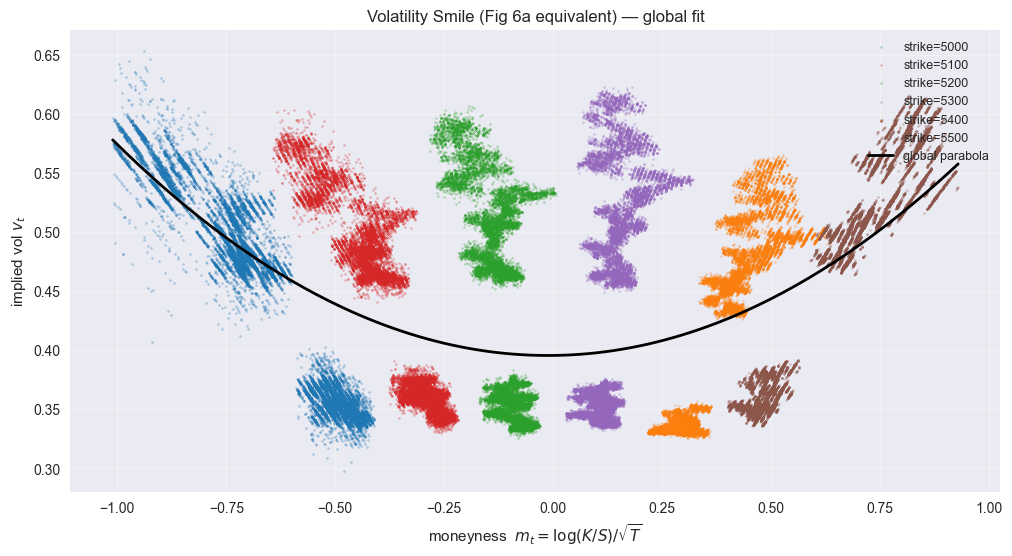


Global parabola: iv = 0.3956 + 0.0044*m + 0.1831*m²
ATM (m=0) IV = 0.3956
Total points: 119,999


In [7]:
# ============================================================
# CELL 6 — Plot the smile (Hedgefort Fig 6a equivalent)
# ============================================================
# Stack all (m, iv) points across all timestamps, color by strike
fig, ax = plt.subplots(figsize=(12, 6))
colors = {5000:'tab:blue', 5100:'tab:red', 5200:'tab:green', 5300:'tab:purple', 5400:'tab:orange', 5500:'tab:brown'}
for K in TRADE_STRIKES:
    m_vals = panel[f'm_{K}'].dropna()
    iv_vals = panel.loc[m_vals.index, f'iv_{K}']
    ax.scatter(m_vals, iv_vals, s=2, alpha=0.3, label=f'strike={K}', color=colors[K])

# Fit a single global parabola across all points
all_m = []; all_iv = []
for K in TRADE_STRIKES:
    m = panel[f'm_{K}'].dropna(); iv = panel.loc[m.index, f'iv_{K}']
    all_m.extend(m.values); all_iv.extend(iv.values)
all_m = np.array(all_m); all_iv = np.array(all_iv)
coef = np.polyfit(all_m, all_iv, 2)
m_grid = np.linspace(all_m.min(), all_m.max(), 200)
ax.plot(m_grid, np.polyval(coef, m_grid), 'k-', lw=2, label='global parabola')
ax.set_xlabel('moneyness  $m_t = \\log(K/S) / \\sqrt{T}$'); ax.set_ylabel('implied vol $v_t$')
ax.set_title('Volatility Smile (Fig 6a equivalent) — global fit')
ax.legend(loc='upper right', fontsize=9)
plt.show()

print(f'\nGlobal parabola: iv = {coef[2]:.4f} + {coef[1]:.4f}*m + {coef[0]:.4f}*m²')
print(f'ATM (m=0) IV = {coef[2]:.4f}')
print(f'Total points: {len(all_m):,}')

### 🔍 Compare with Hedgefort's Fig 6a

**Their plot:** clean, deep U-shape. ATM IV ~0.15. Wings reach 0.25–0.30. Strike groups stack neatly along the parabola.

**What to look for in our plot:**
- Is the curvature (parabola coef on m²) similar?
- Do strike groups stack on the parabola, or are they offset (each strike its own "shelf")?
- The smile shape *across an option's lifetime* lives on the parabola, but each strike traces its own arc as the underlying moves.

In [8]:
# ============================================================
# CELL 7 — Per-row smile fit & residuals (Hedgefort Fig 6b equivalent)
# ============================================================
# At each timestamp, fit a parabola across the 6 active strikes' IVs.
# Residual = observed IV - fitted IV  =>  this is the trading signal in IV space.

def fit_smile_per_row(panel_df, strikes=TRADE_STRIKES):
    n = len(panel_df)
    a_arr = np.full(n, np.nan)   # intercept (ATM IV)
    b_arr = np.full(n, np.nan)   # slope
    c_arr = np.full(n, np.nan)   # curvature
    resids = {K: np.full(n, np.nan) for K in strikes}
    
    m_cols = [panel_df[f'm_{K}'].values for K in strikes]
    iv_cols = [panel_df[f'iv_{K}'].values for K in strikes]
    
    for i in range(n):
        ms = []; ivs = []; idxs = []
        for j, K in enumerate(strikes):
            m = m_cols[j][i]; iv = iv_cols[j][i]
            if not np.isnan(m) and not np.isnan(iv):
                ms.append(m); ivs.append(iv); idxs.append(j)
        if len(ms) < 4: continue
        c, b, a = np.polyfit(ms, ivs, 2)
        a_arr[i] = a; b_arr[i] = b; c_arr[i] = c
        for j, K, m, iv in zip(idxs, [strikes[j] for j in idxs], ms, ivs):
            resids[K][i] = iv - (a + b*m + c*m*m)
    
    out = panel_df.copy()
    out['smile_a'] = a_arr; out['smile_b'] = b_arr; out['smile_c'] = c_arr
    for K in strikes: out[f'resid_{K}'] = resids[K]
    return out

print('Fitting per-row smile (~10s)...')
panel = fit_smile_per_row(panel)
print('Done.')
print(f'  ATM IV (smile_a):  mean = {panel.smile_a.mean():.4f}, std = {panel.smile_a.std():.4f}')
print(f'  Curvature:        mean = {panel.smile_c.mean():.4f}, std = {panel.smile_c.std():.4f}')

Fitting per-row smile (~10s)...
Done.
  ATM IV (smile_a):  mean = 0.4281, std = 0.0844
  Curvature:        mean = 0.0190, std = 0.0210


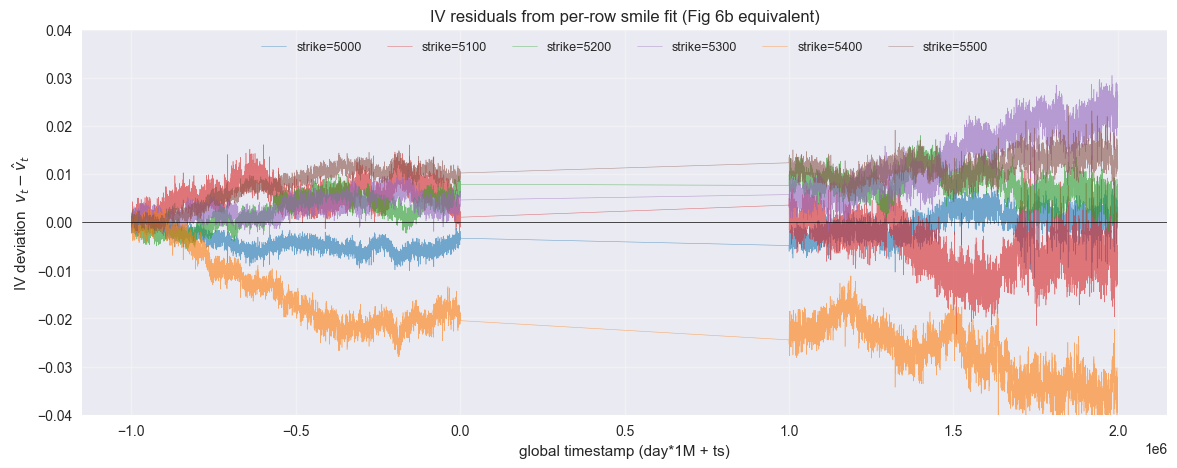


=== Per-strike residual statistics ===
         mean      std      min      max
5000 -0.00227  0.00306 -0.01171  0.00880
5100  0.00002  0.00705 -0.02331  0.01611
5200  0.00510  0.00418 -0.00590  0.01803
5300  0.00837  0.00732 -0.00438  0.03050
5400 -0.02076  0.00960 -0.04866  0.00348
5500  0.00954  0.00388 -0.00196  0.02414

--- Interpretation ---
Hedgefort observed strikes oscillating around 0 (mean reversion in IV-residual space).
A non-zero MEAN residual = persistent fair-IV bias for that strike.
A high STD residual with low autocorrelation = good scalping opportunity.


In [9]:
# ============================================================
# CELL 8 — IV residuals over time (Hedgefort Fig 6b equivalent)
# ============================================================
fig, ax = plt.subplots(figsize=(14, 5))
for K in TRADE_STRIKES:
    ax.plot(panel['t_global'], panel[f'resid_{K}'], lw=0.4, alpha=0.6, label=f'strike={K}', color=colors[K])
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('global timestamp (day*1M + ts)')
ax.set_ylabel('IV deviation  $v_t - \\hat{v}_t$')
ax.set_title('IV residuals from per-row smile fit (Fig 6b equivalent)')
ax.legend(ncol=6, fontsize=9, loc='upper center')
ax.set_ylim(-0.04, 0.04)
plt.show()

print('\n=== Per-strike residual statistics ===')
stats = pd.DataFrame({K: panel[f'resid_{K}'].describe() for K in TRADE_STRIKES}).T
print(stats[['mean', 'std', 'min', 'max']].round(5))
print('\n--- Interpretation ---')
print('Hedgefort observed strikes oscillating around 0 (mean reversion in IV-residual space).')
print('A non-zero MEAN residual = persistent fair-IV bias for that strike.')
print('A high STD residual with low autocorrelation = good scalping opportunity.')

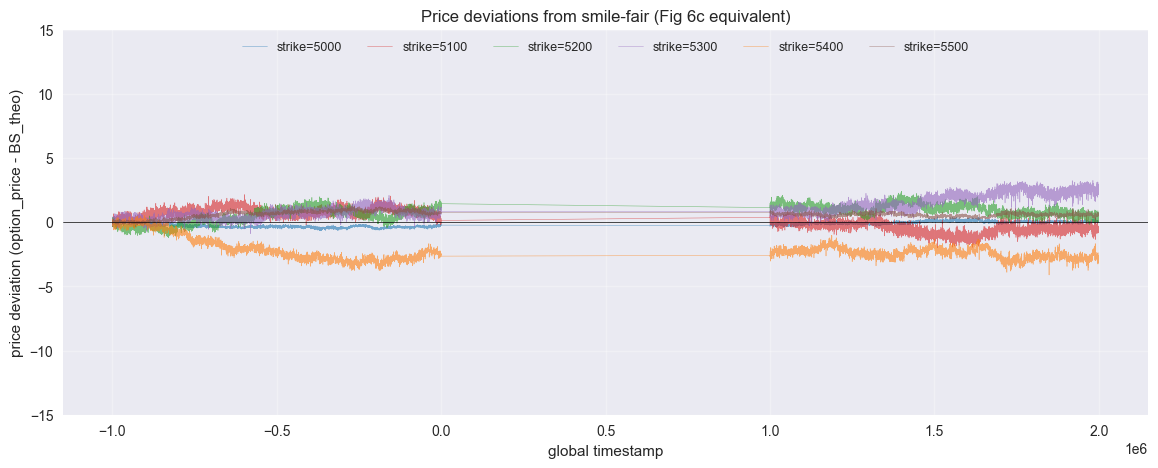


=== Per-strike price-deviation statistics ===
       mean    std    min    max
5000 -0.166  0.195 -0.659  0.430
5100  0.164  0.764 -1.998  2.155
5200  0.724  0.610 -1.213  2.418
5300  1.130  0.797 -0.896  3.261
5400 -2.198  0.818 -4.111  0.526
5500  0.598  0.248 -0.171  1.286


In [10]:
# ============================================================
# CELL 9 — Convert IV deviations to PRICE deviations (Hedgefort Fig 6c)
# ============================================================
# Price deviation = market_price - BS(S, K, T, fitted_IV)
for K in TRADE_STRIKES:
    fair_iv = panel['smile_a'] + panel['smile_b'] * panel[f'm_{K}'] + panel['smile_c'] * panel[f'm_{K}']**2
    panel[f'fair_iv_{K}'] = fair_iv
    fair_price = [bs_call(s, K, t, iv) if (pd.notna(s) and pd.notna(t) and pd.notna(iv) and t>0 and iv>0) else np.nan
                  for s, t, iv in zip(panel['S'].values, panel['T'].values, fair_iv.values)]
    panel[f'fair_p_{K}'] = fair_price
    panel[f'pdev_{K}'] = panel[f'p_{K}'] - panel[f'fair_p_{K}']

fig, ax = plt.subplots(figsize=(14, 5))
for K in TRADE_STRIKES:
    ax.plot(panel['t_global'], panel[f'pdev_{K}'], lw=0.4, alpha=0.6, label=f'strike={K}', color=colors[K])
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('global timestamp'); ax.set_ylabel('price deviation (option_price - BS_theo)')
ax.set_title('Price deviations from smile-fair (Fig 6c equivalent)')
ax.legend(ncol=6, fontsize=9, loc='upper center')
ax.set_ylim(-15, 15)
plt.show()

print('\n=== Per-strike price-deviation statistics ===')
stats = pd.DataFrame({K: panel[f'pdev_{K}'].describe() for K in TRADE_STRIKES}).T
print(stats[['mean', 'std', 'min', 'max']].round(3))

In [11]:
# ============================================================
# CELL 10 — Lag-1 autocorrelation of returns (Hedgefort's stat justification)
# ============================================================
# Quote: "testing for 1-lag negative autocorrelation in returns, strongly supported
#  the existence of exploitable short-term inefficiencies"
#
# We compute corr(r_t, r_{t-1}) for each strike's mid price returns. NEGATIVE = mean-reverting.

print('=== Lag-1 autocorrelation of mid-price returns ===\n')
print(f'{"Strike":<10}{"AR(1) on returns":<20}{"interpretation":<30}')
print('-' * 60)
ar1_results = {}
for K in TRADE_STRIKES + ['VEV_underlying']:
    if K == 'VEV_underlying':
        prices = panel['S'].values
        label = 'VELVETFRUIT (S)'
    else:
        prices = panel[f'p_{K}'].values
        label = f'VEV_{K}'
    rets = np.diff(prices)
    rets = rets[~np.isnan(rets)]
    ar1 = np.corrcoef(rets[:-1], rets[1:])[0,1]
    ar1_results[label] = ar1
    interp = 'mean-reverting ✓' if ar1 < -0.05 else ('momentum' if ar1 > 0.05 else 'random walk-ish')
    print(f'{label:<18}{ar1:>+8.4f}        {interp}')

print('\n--- Hedgefort observed strong negative AR(1) on the 10k strike (the ATM one) ---')
print('--- We expect the same on VEV_5200 / VEV_5300 (our ATM strikes) ---')

=== Lag-1 autocorrelation of mid-price returns ===

Strike    AR(1) on returns    interpretation                
------------------------------------------------------------
VEV_5000           -0.1009        mean-reverting ✓
VEV_5100           -0.0955        mean-reverting ✓
VEV_5200           -0.1307        mean-reverting ✓
VEV_5300           -0.2116        mean-reverting ✓
VEV_5400           -0.2530        mean-reverting ✓
VEV_5500           -0.2463        mean-reverting ✓
VELVETFRUIT (S)    -0.1580        mean-reverting ✓

--- Hedgefort observed strong negative AR(1) on the 10k strike (the ATM one) ---
--- We expect the same on VEV_5200 / VEV_5300 (our ATM strikes) ---


In [12]:
# ============================================================
# CELL 11 — AR(1) on RETURNS NORMALIZED by smile-theo (Fig 7b equivalent)
# ============================================================
# Hedgefort showed that normalizing by theoretical (BS w/ smile IV) makes deviations stationary.
# AR(1) on (price - fair_price) returns should be MORE negative than on raw returns.

print('=== AR(1) comparison: raw price returns vs smile-normalized ===\n')
print(f'{"Strike":<10}{"AR(1) raw":<15}{"AR(1) on dev":<15}{"AR(1) on resid_iv":<20}')
print('-' * 60)
for K in TRADE_STRIKES:
    raw_rets = np.diff(panel[f'p_{K}'].values)
    raw_rets = raw_rets[~np.isnan(raw_rets)]
    ar1_raw = np.corrcoef(raw_rets[:-1], raw_rets[1:])[0,1]
    
    dev = panel[f'pdev_{K}'].dropna().values
    dev_rets = np.diff(dev)
    ar1_dev = np.corrcoef(dev_rets[:-1], dev_rets[1:])[0,1] if len(dev_rets)>10 else np.nan
    
    # Direct AR(1) on the level of resid_iv
    resid = panel[f'resid_{K}'].dropna().values
    ar1_resid = np.corrcoef(resid[:-1], resid[1:])[0,1] if len(resid)>10 else np.nan
    
    print(f'VEV_{K:<5}   {ar1_raw:>+7.4f}      {ar1_dev:>+7.4f}      {ar1_resid:>+7.4f}')

print('\nReading:')
print('  AR(1) raw      → returns of raw mid; if negative → some price-level mean rev')
print('  AR(1) on dev   → returns of (price - smile-theo); shows scalping signal strength')
print('  AR(1) on resid_iv → persistence of IV residual itself (high = trending, low = noisy)')

=== AR(1) comparison: raw price returns vs smile-normalized ===

Strike    AR(1) raw      AR(1) on dev   AR(1) on resid_iv   
------------------------------------------------------------
VEV_5000    -0.1009      -0.4840      +0.8543
VEV_5100    -0.0955      -0.4928      +0.9017
VEV_5200    -0.1307      -0.4814      +0.9067
VEV_5300    -0.2116      -0.4911      +0.9583
VEV_5400    -0.2530      -0.4313      +0.9785
VEV_5500    -0.2463      -0.4471      +0.9425

Reading:
  AR(1) raw      → returns of raw mid; if negative → some price-level mean rev
  AR(1) on dev   → returns of (price - smile-theo); shows scalping signal strength
  AR(1) on resid_iv → persistence of IV residual itself (high = trending, low = noisy)


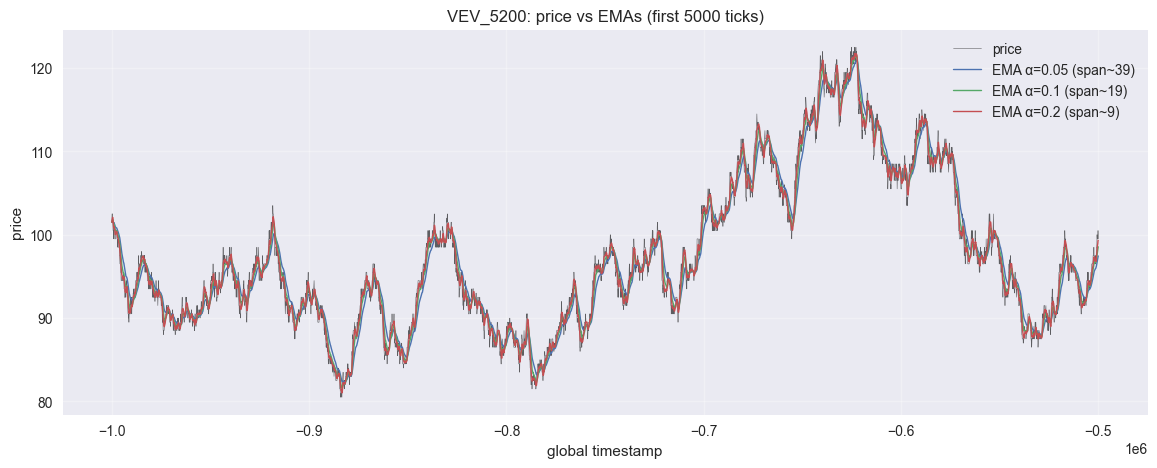

In [14]:
# ============================================================
# CELL 13 — EMA-based mean reversion signal (the simple-without-smile route)
# ============================================================
# Hedgefort's claim: even WITHOUT the smile, watching VEV_5200 (their 10k) and using
# basic EMA-deviation analysis would have surfaced the same edge.
#
# Test: signal = (price - EMA_n) / rolling_std. Trade |z|>1, exit on cross of zero.

def ema(x, alpha):
    out = np.full(len(x), np.nan)
    if len(x) == 0: return out
    out[0] = x[0] if not np.isnan(x[0]) else np.nan
    for i in range(1, len(x)):
        if np.isnan(x[i]):
            out[i] = out[i-1]
        elif np.isnan(out[i-1]):
            out[i] = x[i]
        else:
            out[i] = alpha * x[i] + (1-alpha) * out[i-1]
    return out

# Show EMA on VEV_5200
p = panel[f'p_{ATM}'].values
alphas = [0.05, 0.1, 0.2]   # span ~ 2/alpha - 1 → 39, 19, 9 ticks
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(panel['t_global'][:5000], p[:5000], 'k-', lw=0.4, alpha=0.6, label='price')
for a in alphas:
    e = ema(p, a)
    ax.plot(panel['t_global'][:5000], e[:5000], lw=1, label=f'EMA α={a} (span~{int(2/a-1)})')
ax.set_title(f'VEV_{ATM}: price vs EMAs (first 5000 ticks)')
ax.legend(); ax.set_xlabel('global timestamp'); ax.set_ylabel('price')
plt.show()

In [15]:
# ============================================================
# CELL 14 — Backtest: compare 4 mean-reversion strategies
# ============================================================
# A: Raw price z (rolling-200) — your "existing better" approach
# B: IV rolling z (200)         — IV-space mean rev
# C: Smile residual rolling z   — Hedgefort's signal (in IV space)
# D: Price deviation rolling z  — Hedgefort's signal (in price space, more intuitive)
#
# For each, simulate: enter when |z|>1, exit after H ticks. PnL = mark-to-mark.

def evaluate_signal(z_array, price_array, holding=20, threshold=1.0):
    pnls = []; n = len(z_array) - holding
    for i in range(n):
        z = z_array[i]
        if pd.isna(z) or pd.isna(price_array[i]) or pd.isna(price_array[i+holding]): continue
        if z > threshold: pnls.append(price_array[i] - price_array[i+holding])      # short
        elif z < -threshold: pnls.append(price_array[i+holding] - price_array[i])   # long
    return np.array(pnls)

WINDOW = 200; HOLD = 20; THR = 1.0
results = []
for K in TRADE_STRIKES:
    p = panel[f'p_{K}']
    iv = panel[f'iv_{K}']
    resid = panel[f'resid_{K}']
    pdev = panel[f'pdev_{K}']
    
    rolling = lambda s: ((s - s.rolling(WINDOW, min_periods=50).mean()) / s.rolling(WINDOW, min_periods=50).std())
    
    z_A = rolling(p);     pnl_A = evaluate_signal(z_A.values, p.values, HOLD, THR)
    z_B = rolling(iv);    pnl_B = evaluate_signal(z_B.values, p.values, HOLD, THR)
    z_C = rolling(resid); pnl_C = evaluate_signal(z_C.values, p.values, HOLD, THR)
    z_D = rolling(pdev);  pnl_D = evaluate_signal(z_D.values, p.values, HOLD, THR)
    
    for label, pnl in [('A: raw price z', pnl_A), ('B: IV z', pnl_B),
                       ('C: smile resid z', pnl_C), ('D: price dev z', pnl_D)]:
        if len(pnl) == 0: continue
        results.append({'strategy': label, 'strike': K, 'n_trades': len(pnl),
                       'mean_pnl': pnl.mean(), 'sharpe': pnl.mean()/(pnl.std()+1e-9), 'total_pnl': pnl.sum()})

bt = pd.DataFrame(results)
print(f'=== Backtest: window={WINDOW}, hold={HOLD}, |z|>{THR} ===\n')
print(bt.pivot(index='strike', columns='strategy', values='total_pnl').round(0))
print('\n--- Sharpe per (strike, strategy) ---')
print(bt.pivot(index='strike', columns='strategy', values='sharpe').round(3))
print('\n--- Aggregate (sum of all strikes) ---')
print(bt.groupby('strategy')[['n_trades','total_pnl']].sum())

=== Backtest: window=200, hold=20, |z|>1.0 ===

strategy  A: raw price z  B: IV z  C: smile resid z  D: price dev z
strike                                                             
5000              2540.0   1208.0            2728.0          3068.0
5100              1888.0    768.0            -107.0          -240.0
5200              1856.0   1788.0            1890.0          1944.0
5300              1522.0   1770.0            1417.0          1420.0
5400              1103.0   1316.0            1000.0           893.0
5500              1888.0   1858.0            1023.0          1196.0

--- Sharpe per (strike, strategy) ---
strategy  A: raw price z  B: IV z  C: smile resid z  D: price dev z
strike                                                             
5000               0.029    0.086             0.102           0.111
5100               0.025    0.051            -0.005          -0.010
5200               0.032    0.110             0.098           0.101
5300               0.043    0

In [16]:
# ============================================================
# CELL 15 — Sensitivity: holding period & threshold
# ============================================================
# Find optimal H, THR for the best strategy from Cell 14
best_strat = bt.groupby('strategy')['total_pnl'].sum().idxmax()
print(f'Best strategy from Cell 14: {best_strat}\n')

# Map back to signal column
def signal_of(strat, K):
    p = panel[f'p_{K}']; iv = panel[f'iv_{K}']
    resid = panel[f'resid_{K}']; pdev = panel[f'pdev_{K}']
    rolling = lambda s: ((s - s.rolling(WINDOW, min_periods=50).mean()) / s.rolling(WINDOW, min_periods=50).std())
    if 'raw' in strat: return rolling(p)
    if 'IV z' in strat: return rolling(iv)
    if 'smile' in strat: return rolling(resid)
    return rolling(pdev)

print('Sensitivity grid (total PnL summed across strikes):\n')
print(f'{"H":<5}', end='')
thresholds = [0.5, 1.0, 1.5, 2.0]
for thr in thresholds: print(f'thr={thr:<8}', end='')
print()
for H in [5, 10, 20, 50, 100, 200]:
    print(f'{H:<5}', end='')
    for thr in thresholds:
        total = 0
        for K in TRADE_STRIKES:
            z = signal_of(best_strat, K)
            pnl = evaluate_signal(z.values, panel[f'p_{K}'].values, H, thr)
            total += pnl.sum() if len(pnl) else 0
        print(f'{total:>8.0f}    ', end='')
    print()

Best strategy from Cell 14: A: raw price z

Sensitivity grid (total PnL summed across strikes):

H    thr=0.5     thr=1.0     thr=1.5     thr=2.0     
5        4764        4375        4204        2403    
10       6134        5246        6545        4318    
20      11675       10797       10973        7887    
50      36358       34726       29314       18652    
100     46494       59371       48032       27402    
200    102335       90663       66930       37330    


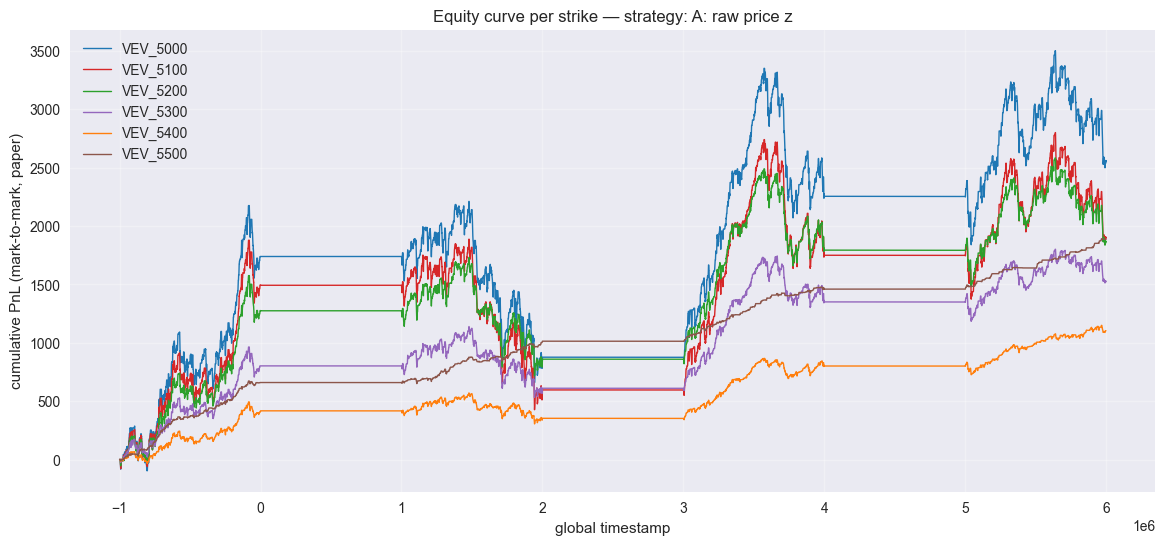

In [17]:
# ============================================================
# CELL 16 — Final picture: equity curve of best strategy per strike
# ============================================================
fig, ax = plt.subplots(figsize=(14, 6))
for K in TRADE_STRIKES:
    z = signal_of(best_strat, K)
    p = panel[f'p_{K}'].values
    z_arr = z.values
    eq = []; cum = 0
    for i in range(len(z_arr) - HOLD):
        if pd.isna(z_arr[i]) or pd.isna(p[i]) or pd.isna(p[i+HOLD]):
            eq.append(cum); continue
        if z_arr[i] > THR: cum += p[i] - p[i+HOLD]
        elif z_arr[i] < -THR: cum += p[i+HOLD] - p[i]
        eq.append(cum)
    ax.plot(panel['t_global'][:len(eq)], eq, lw=1, label=f'VEV_{K}', color=colors[K])
ax.set_title(f'Equity curve per strike — strategy: {best_strat}')
ax.set_xlabel('global timestamp'); ax.set_ylabel('cumulative PnL (mark-to-mark, paper)')
ax.legend()
plt.show()

## Conclusions

After running through this notebook, fill in your answers below as we discuss:

1. **TTE convention found:** _____ days at start of round 4 (probably 7).
2. **Smile shape:** parabola or noise? curvature `c` mean = ____ , std = ____.
3. **Per-strike persistent biases:** which strikes show structural mispricing (mean residual ≠ 0)?
4. **AR(1) on returns:** which strikes show negative autocorrelation (mean reverting)?
5. **Best strategy in the backtest:** _____ . By what margin over the others?
6. **Recommended algo for submission:**
   - Signal: ?
   - Window: ?
   - Threshold: ?
   - Hold: ?
   - Hedge: ?

**Open questions for next iteration:**
- Should we delta-hedge with VELVETFRUIT_EXTRACT?
- Do we hold the smile-fit fair-IV constant across short windows, or refit every tick?
- How do bot-flow patterns (when we get the orders file) align with our z-signal thresholds?